## ResNet

In [16]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from pathlib import Path

### Guide

In pratcital, neural network may **degrade(退化)** when the network getting deeper

The key of **Residual Network** is enabling a module to learn the `residual`(the part of the input that needs to change), instead of learning the full mapping of scratch.

the normal module is like:

$y = F(x)$

the Residual module is like:

$y = F(x) + x$

here `x` is input, `F(x)` is the output of neural network, and `+x` is **shortcut/skip connection(捷径连接)**

the Tensor map of `F(x)` and `x` must be consistent. for example [batch, 64, 32, 32]

however, if the neural network changes the feature size or the tunnel number, the original `x` can't add directly.

so consequentially, `shortcut` will use a **1 * 1 convolution**(with `stride` if necessary) to adjust the shape

#### **Batch Normalization(批量归一化 BN)**

Normalizing the feature maps produced by the convolutional layers, stabilizes
the **activation distribution(数据分布/激活分布)**, enabling faster convergence and more stable training.

`BatchNorm2d` normalizes **each channel independently**. For a given channel, the statistics are computed over the current mini-batch together with the spatial dimensions $(N, C, H, W)$:

$$
\hat{x}=\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}
$$

where:

- $x$: the input activation (a value in the feature map).
- $\mu$: the per-channel mean over the current mini-batch.
- $\sigma^2$: the per-channel variance over the current mini-batch.
- $\epsilon$: a small constant added for numerical stability, preventing division by zero.

After this step the activations are standardized to approximately **zero mean and unit variance**.

#### 2. BatchNorm is more than plain normalization

BatchNorm also has two **learnable** parameters:

$$
y=\gamma\hat{x}+\beta
$$

where:

- $\gamma$: the learnable scale parameter.
- $\beta$: the learnable shift (offset) parameter.

In other words, BatchNorm first standardizes the activations, then applies a learnable affine transform to adjust their distribution.

**Why do this?**

Pure standardization can constrain the network's representational capacity, since it forces every layer's activations into the same fixed distribution. With $\gamma$ and $\beta$, the network can instead learn the activation distribution that works best for it — and $\gamma = 1,\ \beta = 0$ simply recovers the standardized case.

#### 3. Why is BN so common in CNNs?

Three main benefits:

1. **Faster training.** BN keeps the distribution of activations well-behaved throughout training, so optimization is generally more stable and converges faster — larger learning rates become feasible.

2. **More stable training.** It dampens the effect of shifting activation scales across layers: a change in an earlier layer is less likely to destabilize later ones, reducing the chance of exploding/vanishing gradients or divergence.

3. **A mild regularization effect.** BN uses mini-batch statistics, so the normalized value of one sample depends on the other samples in that batch. This injects a small amount of noise and can act as a regularizer in practice.

#### 4. Training mode vs. evaluation mode

In PyTorch, BatchNorm has two working modes.

**Training** — `model.train()`:

```python
model.train()
```

Normalization uses the mean and variance of the **current mini-batch**, while the layer simultaneously updates its **running mean(运行均值)** and **running variance(运行方差)**.

**Evaluation** — `model.eval()`:

```python
model.eval()
```

The current batch statistics are no longer used. Instead, BN relies on the running mean and running variance accumulated during training.

This is exactly why BN behaves differently at train and test time — and why forgetting to switch modes (e.g. leaving a model in `train()` during inference) produces inconsistent outputs.

*Optional: how the running statistics are updated*

$$
\mu_{\mathrm{running}} \leftarrow (1-m)\,\mu_{\mathrm{running}} + m\,\mu_{\mathcal{B}}, \qquad
\sigma^2_{\mathrm{running}} \leftarrow (1-m)\,\sigma^2_{\mathrm{running}} + m\,\sigma^2_{\mathcal{B}}
$$

where $\mu_{\mathcal{B}}, \sigma^2_{\mathcal{B}}$ are the current batch statistics and $m$ is the `momentum` argument of `nn.BatchNorm2d` (default `0.1`). Note that in PyTorch, `momentum` is the weight on the **new** batch statistic, not on the historical one — the opposite convention from some other frameworks.

#### sample

```python
import torch
from torch import nn

x = torch.randn(4, 64, 32, 32)  # batch=4, channels=64, height=32, width=32
main_branch = nn.Conv2d(64, 64, kernel_size=3, padding=1)(x)

print("x shape:", x.shape)
print("F(x) shape:", main_branch.shape)
print("F(x) + x shape:", (main_branch + x).shape)
```

Basic union of ResNet: `BasicBlock`

一个经典的 ResNet-18 / ResNet-34 基本块通常包含：
1. 3×3 卷积 + Batch Normalization + ReLU；
2. 3×3 卷积 + Batch Normalization；
3. 将主分支结果与 shortcut 相加；
4. ReLU 激活。
当输入和输出形状不一样时，shortcut 使用 1×1 卷积进行匹配。

## Define BasicBlock

In [2]:
class BasicBlock(nn.Module):
    '''the basic residual block, expansion=1 means the output channel don't expand extra'''
    expansion=1 # it's a attribute of a class(it's defined outside of __init__)
                # it means the expansion multiple of residual block channel number compare with basic channel number(残差块输出通道数相对于基础通道数的扩张倍数)
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # main branch: two layers of 3*3 convolution
        self.conv1=nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False  # don't use bias in CNN
        )

        self.bn1=nn.BatchNorm2d(out_channels)
        self.relu=nn.ReLU(inplace=True) # modify the input directly, instead of creating a new Tensor

        self.conv2=nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,   # Important : here stride=1
            padding=1,
            bias=False            
        )

        self.bn2=nn.BatchNorm2d(out_channels)

        # shortcut: default identical mapping; if the Tensor size is different, use 1*1 convolution to modify
        if stride!=1 or in_channels!=out_channels:
            self.shortcut=nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut=nn.Identity() #`nn.Identity()` is Identity Layer(恒等映射层)

    def forward(self,x):
        identity=self.shortcut(x)

        out=self.conv1(x)
        out=self.bn1(out)
        out=self.relu(out)

        out=self.conv2(out)
        out=self.bn2(out)

        out=out+identity    # residual connect: F(x) + shortcut(x)

        out=self.relu(out)
        return out

In [3]:
#test the output size of BasicBlock
block_same=BasicBlock(
    in_channels=64,
    out_channels=64,
    stride=1
)
block_downsample=BasicBlock(    # downsampling(下采样)
    in_channels=64,
    out_channels=128,
    stride=2
)

test_x=torch.randn(2, 64, 32, 32)
print("same shape:", block_same(test_x).shape)
print("downsample shape:", block_downsample(test_x).shape)

same shape: torch.Size([2, 64, 32, 32])
downsample shape: torch.Size([2, 128, 16, 16])


<img src="insert_images/resnet_basicblock_shape.png" alt="CNN shape change" width="1000">

## Assemble ResNet-18 with BasicBlock

`ResNet-18` has four stages, each containing two `BasicBlocks`, with channel counts of 64, 128, 256, and 512, respectively.

Here we use `CIFAR-10`, whose images are only 32×32. The original `ImageNet` version of `ResNet` starts with a large 7×7 convolution followed by max pooling, which would shrink the spatial dimensions of CIFAR images too early. We therefore use a **`stem(the small input-preprocessing block at the very front of the network, before the first stage)`** better suited to small images: a 3×3 convolution with stride 1, with no max pooling​ at the beginning.

In [18]:
class ResNet(nn.Module):
    def __init__(self,block,layers,num_classes=10):
        super().__init__()
        self.in_channels=64

        # using 3*3 convolution kernel instead of 7*7+MaxPool for CIFAR-10 images
        self.stem=nn.Sequential(
            nn.Conv2d(3,64,kernel_size=3,stride=1,padding=1,bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.layer1=self._make_layer(block,64,layers[0],stride=1)
        self.layer2=self._make_layer(block,128,layers[1],stride=2)
        self.layer3=self._make_layer(block,256,layers[2],stride=2)
        self.layer4=self._make_layer(block,512,layers[3],stride=2)

        self.avgpool=nn.AdaptiveAvgPool2d((1,1))    # Adaptive Average Pooling(自适应平均池化) AdaptiveAvgPool2d((1,1)) means compress (Hight,Width) to (1,1)
        self.fc=nn.Linear(512*block.expansion,num_classes)  # fc means Full Connection(全连接)

    def _make_layer(self,block,out_channels,num_blocks,stride):
        strides=[stride]+[1]*(num_blocks-1) 
        blocks=[]

        for current_stride in strides:
            blocks.append(block(self.in_channels,out_channels,current_stride))
            self.in_channels=out_channels * block.expansion

        return nn.Sequential(*blocks)   # Important : `*blocks` means unpacking(解包), and `*` means unpacking operator
            # it extract each element of list `blocks`, and pass it to function as individual parameter
    
    def forward(self,x):
        x=self.stem(x)
        x=self.layer1(x)
        x=self.layer2(x)
        x=self.layer3(x)
        x=self.layer4(x)
        x=self.avgpool(x)
        x=torch.flatten(x,1)    # different with `nn.Flatten()` 
        #here `1` means compress the dimention which is hgiher than dim=1 to dim=1. for example: [batch_size(dim=0), 512(dim=1), 1(dim=2), 1(dim=3)] -> [batch_size, 512], and here 512=512*1*1
        x=self.fc(x)

        return x

def resnet18(num_classes=10):
    # it's called ResNet-18 because there is 1 stem, 16 convolutions(8 blocks, each has two convolutions), 1 full connection
    return ResNet(BasicBlock,[2,2,2,2],num_classes=num_classes)

## Check the model structure and outputs

In [19]:
model=resnet18(num_classes=10)
example_images=torch.randn(4,3,32,32)
example_logits=model(example_images)

print(model.__class__.__name__)
print("input shape:", example_images.shape)
print("output shape:", example_logits.shape)
print("number of parameters:", sum(p.numel() for p in model.parameters()))
            # `.numel` is a method of PyTorch, full name is Number of Elements. It returns the number of elements of a Tensor
            # for example: Tensor.Size=[3,2,4], so p.numel=3*2*4=24

ResNet
input shape: torch.Size([4, 3, 32, 32])
output shape: torch.Size([4, 10])
number of parameters: 11173962


## Prepare CIFAR-10 Dataset

CIFAR-10 has **10 classes**: `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, and `truck`.

- **Training set:** 50,000 images
- **Test set:** 10,000 images
- Each image is a **32×32 RGB(Red,Green,Blue)** color image.    Note: every channel of RGB is represented by 8 bits, so there is $2^8=256$ values for each channel(range $[0,255]$). And every pixel can be $[R,G,B]$, such as $[234,255,0]$

We apply two standard data augmentations to the training set:

- `RandomCrop(32, padding=4)` — pad the image first (4 pixels on each side), then randomly crop it back to 32×32. This introduces position / translation variation.
- `RandomHorizontalFlip()` — randomly flip the image horizontally (default probability `p=0.5`).

Both the training and test splits use the **same `Normalize` parameters** (mean and std). Random augmentation is applied **only to the training split**; the test split uses a deterministic transform pipeline (`ToTensor` + `Normalize` only), so evaluation stays reproducible.

- `ToTensor()` - transform the pixel from $0\leq Pixel \leq255$ to $0\leq Pixel \leq1$
- `Normalize(CIFAR_MEAN,CIFAR_STD)`

$$
x''_{c,h,w} = \frac{x'_{c,h,w} - \mu_c}{\sigma_c}, \qquad c \in \{R, G, B\}
$$

where $\mu_c$ and $\sigma_c$ are the mean / standard deviation of channel $c$. Commonly used CIFAR-10 statistics (computed over the **training** split):

$$
\mu = (0.4914,\ 0.4822,\ 0.4465), \qquad \sigma = (0.2470,\ 0.2435,\ 0.2616)
$$

In [ ]:
# common channel mean value and standard deviation of CIFAR-10
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

train_transform=transforms.Compose([
    transforms.RandomCrop(32,padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),  # after `ToTensor()`, 0<=pixel<=1
    transforms.Normalize(CIFAR_MEAN,CIFAR_STD)
])

test_transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN,CIFAR_STD)
])

train_dataset=datasets.CIFAR10(root="./data",train=True,download=True,transform=train_transform)
test_dataset=datasets.CIFAR10(root="./data",train=False,download=True,transform=test_transform)

train_loader=DataLoader(
    train_dataset,
    batch_size=128, # loader.shape=Torch.Size([128,3,32,32])    ([Batch_Size,channel,Height,Wildth])
    shuffle=True,
    #num_workers=0  # `num_worker=0` makes it easier to execute at enviroments like Windows / some Notebook
)

test_loader=DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

classes=train_dataset.classes   # classes is the attribute of CIFAR
print("classes:", classes)
print("train samples:", len(train_dataset)) # training samples(训练样本的数量)
print("test samples:", len(test_dataset))

classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train samples: 50000
test samples: 10000


### Check the training images

> Note: After `Normalize`, pixel values are no longer in $[0, 1]$ (they can be negative or exceed 1). Below, we first **denormalize(反归一化)** the tensor, then display the image.

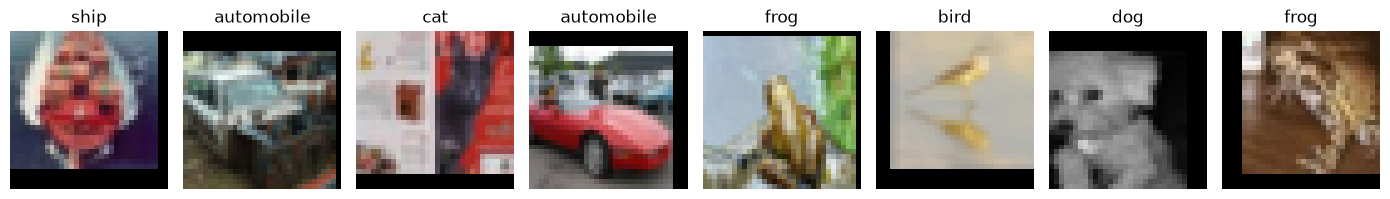

In [ ]:
def show_image(images, labels, class_names, n=8):
    mean=torch.tensor(CIFAR_MEAN).view(3,1,1)   # `.view` changes the shape of tensor, and returns the view(视图) of tensor
    std=torch.tensor(CIFAR_STD).view(3,1,1)     # the number of elements in Tensor must be consistent after `.view`. Before: Tensor.Size([3]) After: Tensor.Size([3,1,1])

    plt.figure(figsize=(14,3))
    for i in range(min(n,len(images))):
        img=(images[i].cpu()*std+mean).clamp(0,1)   # Important : `.clamp(min,max)` is a method for Tensor, which restrict the value of Tensor between min and max. If value<min, value=min; If value>max, value=max
        # `images[i]*std+mean`: denormalize
        plt.subplot(1,n,i+1)    # i+1 means the location of current subplot
        plt.imshow(img.permute(1,2,0))  # Important : `.permute(dim,dim,...)` changes the arrangement of Tensor dimension. Here: permute(1,2,0) means reorder the dim=1 as dim=0(Before: [C,H,W]; Now: [H,W,C])
        plt.title(class_names[labels[i]])
        plt.axis("off")
    plt.tight_layout()  # automatically adjust the space between subplots
    plt.show()

images,labels=next(iter(train_loader))
show_image(images,labels,classes)

#### What does `.view()` acctually do, and what's it for?

`torch.tensor(CIFAR_MEAN)` — or, identically, `torch.tensor(CIFAR_STD)` — turns the 3-element tuple into a 1-D tensor. For the mean:

```python
tensor([0.4914, 0.4822, 0.4465])   # shape: [3]
```

Its shape is `[3]`: one scalar per RGB channel, with no spatial axes yet.

**Now, add the spatial axes with `.view(3, 1, 1)`**

```python
mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
```

which prints as:

```python
tensor([[[0.4914]],
        [[0.4822]],
        [[0.4465]]])              # shape: [3, 1, 1]
```

Its shape is now `[3, 1, 1]` — the channel axis is kept, and two **singleton** (size-1) axes are appended for height and width.

> **The same reshape is applied to `CIFAR_STD`** (using its own three values, e.g. `0.2470, 0.2435, 0.2616`). With $\mathrm{std} \in \mathbb{R}^{3 \times 1 \times 1}$, `(image - mean) / std` divides every pixel in each channel by that channel's own standard deviation.

`.view()` changes only the shape, not the data: $3 = 3 \times 1 \times 1$ elements, so no values are added, dropped, or copied. Those [**singleton(单例维度)**](#singleton) axes are exactly what lets PyTorch broadcast `[3, 1, 1]` against `[3, 32, 32]`.

**Why do it this way?**

A CIFAR-10 image is usually a **3-D tensor** of shape `[3, 32, 32]`, where the axes are:

$$
[\text{channels},\ \text{height},\ \text{width}] \quad (\text{CHW})
$$

The mean, however, is reshaped to `[3, 1, 1]`. This lets us rely on PyTorch's [**broadcasting(广播机制)**](#broadcasting) mechanism: each channel's mean is applied to **every pixel** in the corresponding channel, without explicitly expanding it to `3×32×32`.

For example:

`normalized_image = (image - mean) / std`

Mathematically, this is:

$$
\mathrm{Normalized} = \frac{\mathrm{Image} - \mathrm{Mean}}{\mathrm{Std}}
$$

where, channel by channel:

- All pixels in the **R** channel are subtracted by the R-channel mean.
- All pixels in the **G** channel are subtracted by the G-channel mean.
- All pixels in the **B** channel are subtracted by the B-channel mean.

The same broadcasting rule applies to `std`: with shape `[3, 1, 1]`, each channel is divided by its own standard deviation.

##### What is `Broadcasting` in PyTorch?    <a id="broadcasting"></a>

**Broadcasting is the mechanism that lets PyTorch operate on tensors of different shapes by automatically — and logically — expanding their dimensions.**

```python
a = torch.tensor([
    [1, 2, 3],
    [4, 5, 6]
])

b = torch.tensor([10, 20, 30])
```

```text
a.shape = [2, 3]
b.shape = [3]
```

Now:

```python
c = a + b
```

```python
tensor([[11, 22, 33],
        [14, 25, 36]])
```

`a` has 6 elements, `b` has only 3 — so why can they be added? Because of broadcasting. Logically, PyTorch expands `b` into:

```text
[[10, 20, 30],
 [10, 20, 30]]
```

and then computes:

```text
     A              B             A + B
[ 1  2  3 ]     [ 10 20 30 ]     [ 11 22 33 ]
[ 4  5  6 ]  +  [ 10 20 30 ]  =  [ 14 25 36 ]
```

> **Note:** *logically* is the important word. PyTorch usually does **not** physically copy the data (it uses a stride of 0), so broadcasting is cheap in both memory and time.

**Broadcasting rules**

PyTorch decides whether two tensors are broadcastable using two rules:

1. **Compare dimensions starting from the rightmost (trailing) axis.** A missing leading axis is treated as size 1.
2. **Two dimensions are compatible if they are equal, or if one of them is 1.**

| Tensor A | Tensor B | Broadcastable? |
|---|---|:---:|
| `[3, 4]` | `[3, 4]` | ✅ |
| `[3, 4]` | `[1, 4]` | ✅ |
| `[3, 4]` | `[3, 1]` | ✅ |
| `[3, 4]` | `[4]` | ✅ |
| `[3, 4]` | `[2, 4]` | ❌ |

**Why do `[3, 4]` and `[4]` work?** Compare right to left:

```text
A:   3   4
B:       4
```

which is read as:

```text
A:   3   4
B:   1   4      # the missing leading axis is padded with 1
```

- Last axis: `4` vs `4` → equal ✅
- Second-to-last axis: `3` vs `1` → one of them is 1 ✅

Hence the two shapes are broadcastable. (In the last row of the table, `3` vs `2` is neither equal nor 1, so it fails.)

> **Back to CIFAR-10:** `image` is `[3, 32, 32]` and `mean` / `std` are `[3, 1, 1]`. Right-aligned: `(3, 32, 32)` vs `(3, 1, 1)` → `3 = 3`, `32` vs `1` ✅, `32` vs `1` ✅. That is precisely why `.view(3, 1, 1)` was necessary — a plain `[3]` would align against the **width** axis (`32`), which is neither equal nor 1, and PyTorch would raise a shape error.

##### What is `singleton`？     <a id="singleton"></a>

**A singleton dimension is a dimension whose size is 1.**

```python
x = torch.tensor([1, 2, 3]).view(3, 1, 1)
print(x.shape)
```

```python
torch.Size([3, 1, 1])
```

There are three axes:

| Axis | Size | Singleton dimension? |
|---|:---:|:---:|
| 1st | 3 | ❌ |
| 2nd | 1 | ✅ |
| 3rd | 1 | ✅ |

So `[3, 1, 1]` contains **two** singleton dimensions.

## Define training function and evaluate function

In [8]:
def train_one_epoch(model,loader,loss_fn,optimizer,device,max_batches=None):
    model.train()
    total_loss=0.0
    total_correct=0
    total_samples=0

    for batch_idx, (images,labels) in enumerate(loader):
        if max_batches is not None and batch_idx >= max_batches:
            break

        images=images.to(device)
        labels=labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits=model(images)
        loss=loss_fn(logits,labels)
        loss.backward()
        optimizer.step()

        batch_size=labels.size(0)
        total_loss+=loss.item()*batch_size
        total_correct+=(logits.argmax(dim=1)==labels).sum().item()
        total_samples+=batch_size

    return total_loss/total_samples, total_correct/total_samples

@torch.no_grad()    # decorator
def evaluate(model,loader,loss_fn,device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss = loss_fn(logits, labels)
    
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size
    
    return total_loss / total_samples, total_correct / total_samples

## Training Model

1. `optimizer.zero_grad()`: clear up the gradients of the late iteration.

2. `logits=model(feature)`: forward propagation, get the original output.

3. `loss=loss_fn(logits,labels)`: calculate the loss.

4. `loss.backward()`: backpropagation for calculating the gradients.

5. `optimizer.step()`: upgrade the parameters according to gradients.

- Here we add `weight_decay` and `CosineAnnealingLR`

6. `weight_decay(权重衰减)`: a common method for weights regularization.

7. `CosineAnnealingLR`: adjust learning rate gradually while training.

Here, we meet `scheduler/Learning Rate Scheduler(学习率调度器)` for the first time.

In [9]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [20]:
model=resnet18(num_classes=10).to(device)
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)

epochs=5    # the data is huge
batches=80
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)    # lr is defined inside optimizer, so the first parameter of CosineAnnealingLR is optimizer


#### Explain `scheduler`, `CosineAnnealingLR` and `weight_decay`

##### 1. What `T_max` means

```python
T_max = epochs
```

Here `epochs = 5`, so `T_max = 5`.

It is the number of **scheduler steps** needed to complete one cosine annealing cycle. In the usual pattern used in this code — calling `scheduler.step()` once per epoch — the learning rate completes one full cosine descent over 5 epochs.

---

##### 2. How does the learning rate change?

Assume:

```python
lr      = 0.001      # eta_max, initial learning rate
eta_min = 0          # minimum learning rate (default)
T_max   = 5
```

The learning rate then evolves roughly as follows:

| Epoch | Learning Rate |
|---|---:|
| Start | 0.001 |
| 1 | 0.000905 |
| 2 | 0.000655 |
| 3 | 0.000345 |
| 4 | 0.000095 |
| 5 | 0 |

These values follow the **cosine annealing formula(余弦退火公式)**:

$$
\eta_t = \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})
\left(1 + \cos\frac{\pi t}{T_{\max}}\right)
$$

where:

- $\eta_t$: the current learning rate.
- $\eta_{\max}$: the initial (maximum) learning rate.
- $\eta_{\min}$: the minimum learning rate, `0` by default.
- $t$: the current scheduler step.
- $T_{\max}$: the length of the cosine cycle.

> **Note:** the table above assumes `scheduler.step()` is called **once at the end of each epoch**.

---

##### 3. Very important: the scheduler must be called manually!

You defined:

```python
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
)
```

This only **creates** the learning-rate scheduler. **It does not run automatically.** You still have to call `scheduler.step()` inside the training loop:

```python
for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

    scheduler.step()      # once per epoch, after the inner loop
```

Two different things:

- `optimizer.step()` — updates the **model parameters**.
- `scheduler.step()` — adjusts the **learning rate**.

> **They are not the same thing.** When the LR is updated once per epoch, place `scheduler.step()` after that epoch's training loop finishes — i.e. outside the inner batch loop.

---

##### 4. What is Weight Decay?

Now look at:

```python
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)
```

`weight_decay=1e-4` is **weight decay**, a **regularization** technique.

###### 4.1 Why do we need Weight Decay? (Overfitting)

First, one question: what is **overfitting**?

Suppose you train a model to tell cats from dogs.

The training set has 1,000 images.

After training:

- Training accuracy: **99%**
- Test accuracy: **65%**

What does this tell us?

The model does very well on the training set, but performs poorly on new images it has never seen before.

That is overfitting.

The model may have memorized the details of the training data too heavily, instead of truly learning features that generalize.

###### 4.2 How does Weight Decay help?

A neural network has many parameters (weights). For example:

```text
Weight 1 =   0.5
Weight 2 =   2.3
Weight 3 =  15.8
Weight 4 = -20.5
```

The idea behind weight decay is:

> **Keep the model weights from growing too large**, which reduces overfitting to the training data.

You can think of it as adding a constraint to the model:

> Do not let the parameters grow without bound.

Mathematically, L2 regularization usually adds a penalty term to the original loss:

$$
L_{\text{total}} = L_{\text{original}} + \lambda \sum_i w_i^2
$$

where:

- $L_{\text{original}}$: the original loss function.
- $w_i$: a weight parameter of the model.
- $\lambda$: the regularization strength.

> The larger the weights, the larger the penalty.

###### 4.3 What does `weight_decay=1e-4` mean?

```python
weight_decay = 1e-4
```

equals

$$
0.0001
$$

It controls the **strength** of the weight decay. As a rough guide:

| `weight_decay` | Meaning |
|---|---|
| `0` | no weight decay |
| `1e-5` | weak weight decay |
| `1e-4` | a common setting |
| `1e-3` | stronger weight decay |
| `1e-2` | very strong weight decay |

> **Note:** this table is only a reference for building intuition, **not a fixed standard**. The actual effect depends on the model, the dataset, and the optimizer.

Too much weight decay can also keep the model from learning enough features, leading to **underfitting(欠拟合)**.

##### 4.4 Why `AdamW` instead of `Adam`?

You are using:

```python
torch.optim.AdamW()
```

rather than:

```python
torch.optim.Adam()
```

Both are optimizers, but `AdamW` handles weight decay more sensibly:

- **Adam:** in the traditional implementation, weight decay is coupled with the gradient update (equivalent to the L2 penalty added to the loss in §4.2).
- **AdamW:** **decouples** weight decay from the gradient update (**decoupled weight decay**) — this is exactly where the **W** in `AdamW` comes from.

In practice, the decay is applied directly to the parameters, independent of the adaptive learning-rate terms. That is why `weight_decay` behaves like the regularization strength described above, instead of being entangled with the gradient. `AdamW` is very common in modern deep learning tasks.

### Start training

In [12]:
history={"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1,epochs+1):
    train_loss, train_acc=train_one_epoch(model,train_loader,loss_fn,optimizer,device,max_batches=batches)
    test_loss,test_acc=evaluate(model,test_loader,loss_fn,device)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    print(
        f"epoch [{epoch: 02d}/{epochs}]"
        f"train_loss={train_loss:.4f}, train_acc={train_acc:.2%} | "
        f"test_loss={test_loss:.4f}, test_acc={test_acc:.2%}"
    )

epoch [ 1/5]train_loss=1.8313, train_acc=33.03% | test_loss=1.5387, test_acc=43.33%
epoch [ 2/5]train_loss=1.4922, train_acc=45.34% | test_loss=1.4592, test_acc=46.65%
epoch [ 3/5]train_loss=1.3187, train_acc=51.65% | test_loss=1.4244, test_acc=48.87%
epoch [ 4/5]train_loss=1.1677, train_acc=58.26% | test_loss=1.1614, test_acc=58.73%
epoch [ 5/5]train_loss=1.0471, train_acc=62.05% | test_loss=0.9822, test_acc=64.57%


## Visualizing the training curve

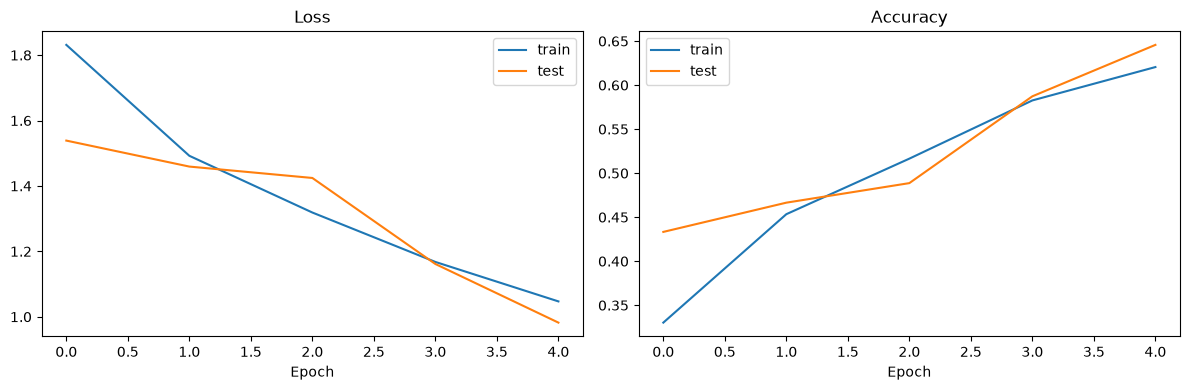

In [15]:
fig, axes=plt.subplots(1,2,figsize=(12,4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["test_loss"], label="test")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["test_acc"], label="test")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


## Check the prediction

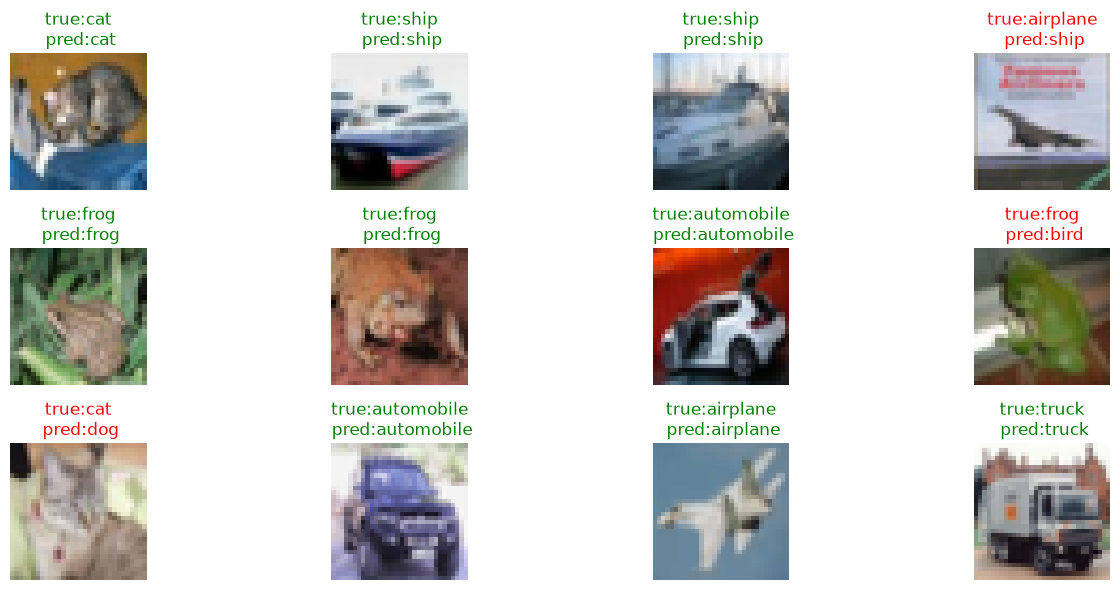

In [13]:
@torch.no_grad()
def show_predictions(model,loader,class_names,device,n=12):
    model.eval()
    images,labels=next(iter(loader))
    logits=model(images[:n].to(device))     # the precondition is `model=model.to(device)`
    predictions=logits.argmax(dim=1).cpu()

    mean=torch.tensor(CIFAR_MEAN).view(3,1,1)
    std=torch.tensor(CIFAR_STD).view(3,1,1)

    plt.figure(figsize=(14,6))
    for i in range(min(n,len(images))):
        img=(images[i]*std+mean).clamp(0,1)
        true_name=class_names[labels[i]]
        pred_name=class_names[predictions[i]]
        color="green" if true_name==pred_name else "red"

        plt.subplot(3,4,i+1)
        plt.imshow(img.permute(1,2,0))
        plt.title(f"true:{true_name}\n pred:{pred_name}",color=color)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(model,test_loader,classes,device)

## Save the trained model parameters

In [21]:
model_path = Path("resnet18_cifar10.pth")
torch.save(model.state_dict(), model_path)
print("saved to:", model_path.resolve())

# create an identical model structure, then load the parameters
loaded_model = resnet18(num_classes=10).to(device)
state_dict = torch.load(model_path, map_location=device)
loaded_model.load_state_dict(state_dict)
loaded_model.eval()
print("model loaded")

saved to: /data/zyhwork/ML/neural_network/ResNet/resnet18_cifar10.pth
model loaded


Next: **Transfer Learning(迁移学习)**